## CrossVQA Pooled 3-Way Partitioning & Visual Similarity Gate (`ALT_THREE_SPLITS`)

This production notebook executes the **De Novo Pooled 3-Way Group-First Splitting Pipeline** specified in [`PLAN/0044_11112026_pipeline_plan_ALT-THREE-SPLITS.md`](../../PLAN/0044_11112026_pipeline_plan_ALT-THREE-SPLITS.md):

1. **Unified Corpus Pooling & Top-Hierarchy Aggregation (Phase 1 & 2a):**
   - Pools official `train` and `validation` into a single unified population (**84,414 queries**: DocVQA `44,812` | TextVQA `39,602`).
   - **DocVQA:** Aggregates globally by parent document (`ucsf_document_id`, `5,687` unique documents), unifying the `523` parent documents that historically straddled official `train` and `validation`.
   - **TextVQA:** Aggregates globally by scene image (`image_id`, `25,119` unique images).
2. **2-Stage Group-First Partitioning & Statistical Power Floors (Phase 2b):**
   - **Heavy-Tail Outlier Guardrail ($|z| > 3.0$):** Pins `79` DocVQA mega-documents (`7,714` queries) strictly to `NEW_train`.
   - **Stage 1 (`NEW_test`):** Carves out $\approx 11.0\%$ ($N \ge 4,600$, $\text{MoE}_{95\%} \le \pm 1.45\%$).
   - **Stage 2 (`NEW_validation`):** Carves out $\approx 8.0\%$ ($N \ge 3,200$, $\text{MoE}_{95\%} \le \pm 1.75\%$).
   - **Stage 3 (`NEW_train`):** Retains $\approx 80.5\%$ of total queries ($>31.8\text{k}$ TextVQA / $>36.1\text{k}$ DocVQA).
3. **In-VM Visual Similarity Gate (Phase 3):**
   - Computes 64-bit `pHash` across images in `/content/data/` ($d_H \le 3$) and applies NetworkX Disjoint Set Union (`super_group_key`) to prevent burst-photo or duplicate-scan leakage.
4. **Artifact Export, GitHub Sync & Optional HF Hub Materialization (Phase 4 & 6):**
   - Exports `docvqa_document_aggregates_pooled`, `textvqa_image_aggregates_pooled`, and `crossvqa_split_manifest_pooled.parquet` to `DATA_PIPELINE/ALT_THREE_SPLITS/splits/`.

In [1]:
# ==============================================================================
# 1. ENVIRONMENT SETUP, LOCKED DECISION CONSTANTS & STYLING
# ==============================================================================
import gc
import json
import math
import os
import sys
import time
import warnings
from pathlib import Path

try:
    import google.colab  # type: ignore
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    import subprocess
    print("[Colab VM] Installing / verifying Polars, HF Transfer, ImageHash, NetworkX, and Tabulate...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-U", "polars", "hf_transfer", "tabulate", "imagehash", "networkx", "pillow"],
        check=True,
    )

import numpy as np
import polars as pl
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from huggingface_hub import snapshot_download
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Locked Decision Parameters per PLAN/0044_11112026_pipeline_plan_ALT-THREE-SPLITS.md ---
TARGET_TEST_SHARE = 0.11       # 11.00% target share -> NEW_test (MoE_95% <= +-1.45%)
TARGET_VAL_SHARE  = 0.08       #  8.00% target share -> NEW_validation (MoE_95% <= +-1.75%)
MIN_TEST_QUERIES  = 4600       # Statistical power floor for NEW_test (MoE_95% <= +-1.45%)
MIN_VAL_QUERIES   = 3200       # Statistical power floor for NEW_validation (MoE_95% <= +-1.75%)
Z_THRESHOLD       = 3.0        # Pin |z| > 3.0 heavy-tail mega-documents strictly to NEW_train
RANDOM_SEED       = 42         # Deterministic cluster sampling seed
PHASH_HAMMING_CUT = 3          # 64-bit pHash Hamming distance threshold (d_H <= 3)

# --- Resolve Optional HF_TOKEN ---
HF_TOKEN = os.environ.get("HF_TOKEN") or None
if IN_COLAB and HF_TOKEN is None:
    try:
        from google.colab import userdata  # type: ignore
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

# --- Relative Path Configuration (Strictly Relative to Project Root) ---
if Path.cwd().name == "ALT_THREE_SPLITS":
    os.chdir("../..")
elif Path.cwd().name == "DATA_PIPELINE":
    os.chdir("..")

REL_ROOT = Path("DATA_PIPELINE/ALT_THREE_SPLITS")
REL_CACHE_DIR = Path("DATA_PIPELINE/cache")
REL_FIG_DIR = REL_ROOT / "figures"
REL_SPLIT_DIR = REL_ROOT / "splits"

for _d in (REL_CACHE_DIR, REL_FIG_DIR, REL_SPLIT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

PLOT_THEME = "light"

def apply_plot_theme(theme: str = "dark") -> dict:
    if theme == "dark":
        plt.style.use("dark_background")
        palette = {
            "textvqa": "#FB923C", "docvqa": "#38BDF8",
            "train": "#60A5FA", "val": "#34D399", "test": "#F472B6",
            "accent": "#FBBF24", "slate": "#52525B", "text": "#F4F4F5",
            "bg_fig": "#18181B", "bg_ax": "#27272A", "grid": "#3F3F46",
        }
        plt.rcParams.update({
            "figure.facecolor": palette["bg_fig"], "axes.facecolor": palette["bg_ax"],
            "axes.edgecolor": palette["slate"], "axes.labelcolor": palette["text"],
            "xtick.color": palette["text"], "ytick.color": palette["text"],
            "text.color": palette["text"], "grid.color": palette["grid"], "grid.alpha": 0.45,
            "legend.facecolor": palette["bg_ax"], "legend.edgecolor": palette["slate"],
            "figure.dpi": 130, "savefig.dpi": 150, "axes.titleweight": "bold",
            "axes.labelweight": "bold", "axes.linewidth": 1.0,
        })
    else:
        sns.set_theme(style="whitegrid", palette="colorblind")
        palette = {
            "textvqa": "#D55E00", "docvqa": "#0072B2",
            "train": "#0072B2", "val": "#009E73", "test": "#CC79A7",
            "accent": "#E69F00", "slate": "#222222", "text": "#111111",
            "bg_fig": "#FFFFFF", "bg_ax": "#FFFFFF", "grid": "#E0E0E0",
        }
        plt.rcParams.update({
            "figure.facecolor": palette["bg_fig"], "axes.facecolor": palette["bg_ax"],
            "axes.edgecolor": palette["slate"], "axes.labelcolor": palette["text"],
            "xtick.color": palette["text"], "ytick.color": palette["text"],
            "text.color": palette["text"], "grid.color": palette["grid"], "grid.alpha": 0.6,
            "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D1D5DB",
            "figure.dpi": 130, "savefig.dpi": 150, "axes.titleweight": "bold",
            "axes.labelweight": "bold", "axes.linewidth": 1.0,
        })
    return palette

PALETTE = apply_plot_theme(PLOT_THEME)

try:
    from tabulate import tabulate
except ImportError:
    tabulate = None

def display_markdown_table(df: pl.DataFrame, title: str | None = None) -> None:
    if title:
        display(Markdown(title))
    clean_cols = [c.replace("|", r"\|") for c in df.columns]
    df_clean = df.rename(dict(zip(df.columns, clean_cols)))
    if tabulate is not None:
        display(Markdown(tabulate(df_clean.to_dicts(), headers="keys", tablefmt="pipe")))
    else:
        display(Markdown(df_clean.to_pandas().to_markdown(index=False)))

print(f"Environment: {'Google Colab VM' if IN_COLAB else 'Local Runtime'} | Polars {pl.__version__}")
print(f"Locked Pooled Protocol -> Test: {TARGET_TEST_SHARE*100:.1f}% (>={MIN_TEST_QUERIES}) | Val: {TARGET_VAL_SHARE*100:.1f}% (>={MIN_VAL_QUERIES}) | Outlier Pin: |z| > {Z_THRESHOLD} | Seed: {RANDOM_SEED}")

Environment: Local Runtime | Polars 1.40.1
Locked Pooled Protocol -> Test: 11.0% (>=4600) | Val: 8.0% (>=3200) | Outlier Pin: |z| > 3.0 | Seed: 42


In [2]:
# ==============================================================================
# 2. PHASE 1A: ENSURE CANONICAL PARQUET SHARDS OR SHARED CACHE ON RUNTIME DISK
# ==============================================================================
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "1"

HF_DATASETS = {
    "textvqa": {
        "repo_id": "gamusa/textvqa-canonical",
        "revision": "d1dcf73eda54e82e84f69d0265f3a9e663420583",
        "label": "TextVQA",
        "domain": "scene_text",
        "local_dir": Path("/content/data/textvqa") if IN_COLAB else Path("DATA_PIPELINE/data/textvqa"),
        "cache_file": REL_CACHE_DIR / "textvqa_polars_meta.parquet",
        "fallback_index": REL_CACHE_DIR / "textvqa_leakage_index.parquet",
    },
    "docvqa": {
        "repo_id": "gamusa/docvqa-canonical",
        "revision": "86e379d727ab104301e3639b909bfbddb0af6376",
        "label": "DocVQA",
        "domain": "document_text",
        "local_dir": Path("/content/data/docvqa") if IN_COLAB else Path("DATA_PIPELINE/data/docvqa"),
        "cache_file": REL_CACHE_DIR / "docvqa_polars_meta.parquet",
        "fallback_index": REL_CACHE_DIR / "docvqa_leakage_index.parquet",
    },
}

# Set force_download_shards=True on Colab VM when running raw pixel pHash sweeps
FORCE_SHARD_DOWNLOAD = False

def ensure_dataset_on_vm(ds_key: str, force_download: bool = False) -> Path:
    cfg = HF_DATASETS[ds_key]
    target_dir = cfg["local_dir"]
    target_dir.mkdir(parents=True, exist_ok=True)

    existing_shards = list(target_dir.glob("**/*.parquet"))
    if existing_shards and not force_download:
        print(f"[{cfg['label']}] Reusing {len(existing_shards)} local Parquet shards in {target_dir.as_posix()}")
        return target_dir

    if (cfg["cache_file"].exists() or cfg["fallback_index"].exists()) and not force_download:
        print(f"[{cfg['label']}] Metadata cache found in {REL_CACHE_DIR.as_posix()} -> skipping 15GB raw shard download.")
        return target_dir

    print(f"[{cfg['label']}] Downloading shards from {cfg['repo_id']}@{cfg['revision'][:10]}...")
    t0 = time.time()
    snapshot_download(
        repo_id=cfg["repo_id"],
        repo_type="dataset",
        revision=cfg["revision"],
        local_dir=str(target_dir),
        allow_patterns=["*.parquet", "**/*.parquet"],
        max_workers=8,
        token=HF_TOKEN,
    )
    shards = list(target_dir.glob("**/*.parquet"))
    print(f"[{cfg['label']}] Downloaded {len(shards)} shards in {time.time() - t0:.1f}s")
    return target_dir

for _k in HF_DATASETS:
    ensure_dataset_on_vm(_k, force_download=FORCE_SHARD_DOWNLOAD)

[TextVQA] Metadata cache found in DATA_PIPELINE/cache -> skipping 15GB raw shard download.
[DocVQA] Metadata cache found in DATA_PIPELINE/cache -> skipping 15GB raw shard download.


In [3]:
# ==============================================================================
# 3. PHASE 1B: LIGHTWEIGHT POLARS SCAN & HIERARCHY KEY EXTRACTION
# ==============================================================================
REQUIRED_COLUMNS = [
    "sample_id",
    "domain_type",
    "split",
    "question_id",
    "image_id",
    "ocr_tokens",
    "metadata",
]

def scan_minimal_metadata_polars(ds_key: str, force_refresh: bool = False) -> pl.DataFrame:
    cfg = HF_DATASETS[ds_key]
    cache_path = cfg["cache_file"]
    fallback_idx = cfg["fallback_index"]

    if cache_path.exists() and not force_refresh:
        df = pl.read_parquet(cache_path)
        print(f"[{cfg['label']}] Loaded cached metadata: {cache_path.as_posix()} ({df.height:,} rows)")
        return df

    if fallback_idx.exists() and not force_refresh:
        df_idx = pl.read_parquet(fallback_idx)
        if ds_key == "docvqa":
            df = df_idx.select([
                "sample_id", "domain_type", "split", "question_id", "image_id",
                pl.col("ocr_token_count").cast(pl.UInt16),
                "ucsf_document_id",
                pl.col("ucsf_document_page_no").cast(pl.UInt16, strict=False).fill_null(1).alias("ucsf_page_no"),
            ])
        else:
            df = df_idx.select([
                "sample_id", "domain_type", "split", "question_id", "image_id",
                pl.col("ocr_token_count").cast(pl.UInt16),
            ])
        df.write_parquet(cache_path, compression="zstd")
        print(f"[{cfg['label']}] Built metadata cache from leakage index -> {cache_path.as_posix()} ({df.height:,} rows)")
        return df

    data_dir = cfg["local_dir"]
    local_shards = list(data_dir.glob("**/*.parquet"))
    if not local_shards:
        raise FileNotFoundError(f"No Parquet shards or cache found for {ds_key}. Set FORCE_SHARD_DOWNLOAD=True in Cell 2!")

    schema = pq.read_schema(local_shards[0])
    avail_cols = [c for c in REQUIRED_COLUMNS if c in schema.names]

    df = (
        pl.scan_parquet(str(data_dir / "**" / "*.parquet"))
        .select(avail_cols)
        .filter(pl.col("split").is_in(["train", "validation"]))
        .collect()
    )

    exprs = [
        pl.col("ocr_tokens").list.len().fill_null(0).cast(pl.UInt16).alias("ocr_token_count"),
    ]
    if ds_key == "docvqa":
        exprs.extend([
            pl.col("metadata")
            .str.json_path_match("$.ucsf_document_id")
            .fill_null(pl.col("image_id").str.extract(r"^([^_]+)", 1))
            .alias("ucsf_document_id"),
            pl.col("metadata")
            .str.json_path_match("$.ucsf_document_page_no")
            .cast(pl.UInt16, strict=False)
            .fill_null(1)
            .alias("ucsf_page_no"),
        ])

    drop_cols = [c for c in ("ocr_tokens", "metadata") if c in df.columns]
    df = df.with_columns(exprs).drop(drop_cols)
    df.write_parquet(cache_path, compression="zstd")
    print(f"[{cfg['label']}] Extracted minimal metadata ({df.height:,} rows) -> {cache_path.as_posix()}")
    return df

df_textvqa = scan_minimal_metadata_polars("textvqa")
df_docvqa = scan_minimal_metadata_polars("docvqa")

[TextVQA] Loaded cached metadata: DATA_PIPELINE/cache/textvqa_polars_meta.parquet (39,602 rows)
[DocVQA] Loaded cached metadata: DATA_PIPELINE/cache/docvqa_polars_meta.parquet (44,812 rows)


### Phase 2a: Global Top-Hierarchy Group Aggregation (Unified Pool)
Unlike the baseline pipeline (which grouped by `[split, group_key]` to preserve official validation), the `ALT_THREE_SPLITS` protocol removes `split` from the grouping keys and aggregates **globally across all 84,414 queries**:
- **DocVQA Top Group (`ucsf_document_id`):** Collapses `5,272` official train documents and `938` official validation documents into **`5,687` unique parent documents**—automatically unifying the `523` multi-page documents that previously leaked across official `train` and `validation`.
- **TextVQA Top Group (`image_id`):** Aggregates all **`25,119` unique scene images** (`21,953` train + `3,166` validation).

In [4]:
# ==============================================================================
# 4. PHASE 2A: GLOBAL AGGREGATION BY TOP-HIERARCHY GROUP (UNIFIED POOL)
# ==============================================================================

# 1. DocVQA: Group strictly by ucsf_document_id across the entire pooled corpus
docvqa_groups_raw = (
    df_docvqa
    .group_by("ucsf_document_id")
    .agg([
        pl.col("image_id").n_unique().cast(pl.UInt16).alias("image_count"),
        pl.len().cast(pl.UInt16).alias("question_count"),
        (pl.col("ocr_token_count") == 0).sum().cast(pl.UInt16).alias("zero_ocr_count"),
        pl.col("ocr_token_count").mean().round(2).alias("mean_ocr_tokens"),
        pl.col("split").unique().sort().str.join("+").alias("official_split_origin"),
    ])
    .sort(["question_count", "image_count", "ucsf_document_id"], descending=[True, True, False])
)

# 2. TextVQA: Group strictly by image_id across the entire pooled corpus
textvqa_groups_raw = (
    df_textvqa
    .group_by("image_id")
    .agg([
        pl.len().cast(pl.UInt16).alias("question_count"),
        (pl.col("ocr_token_count") == 0).sum().cast(pl.UInt16).alias("zero_ocr_count"),
        pl.col("ocr_token_count").mean().round(2).alias("mean_ocr_tokens"),
        pl.col("split").unique().sort().str.join("+").alias("official_split_origin"),
    ])
    .sort(["question_count", "image_id"], descending=[True, False])
)

n_doc_bridged = docvqa_groups_raw.filter(pl.col("official_split_origin") == "train+validation").height
n_txt_bridged = textvqa_groups_raw.filter(pl.col("official_split_origin") == "train+validation").height

print(f"DocVQA Unified Parent Documents: {docvqa_groups_raw.height:,} (Unified train+validation bridge docs: {n_doc_bridged:,})")
print(f"TextVQA Unified Scene Images:    {textvqa_groups_raw.height:,} (Unified train+validation bridge images: {n_txt_bridged:,})")

display_markdown_table(
    docvqa_groups_raw.head(10),
    "#### Preview: Top 10 Pooled DocVQA Parent Documents (`ucsf_document_id`)"
)
display_markdown_table(
    textvqa_groups_raw.head(10),
    "#### Preview: Top 10 Pooled TextVQA Scene Images (`image_id`)"
)

DocVQA Unified Parent Documents: 5,687 (Unified train+validation bridge docs: 523)
TextVQA Unified Scene Images:    25,119 (Unified train+validation bridge images: 0)


#### Preview: Top 10 Pooled DocVQA Parent Documents (`ucsf_document_id`)

| ucsf_document_id   |   image_count |   question_count |   zero_ocr_count |   mean_ocr_tokens | official_split_origin   |
|:-------------------|--------------:|-----------------:|-----------------:|------------------:|:------------------------|
| qjgn0226           |           140 |              762 |                0 |             89.2  | train+validation        |
| xrcy0227           |            80 |              345 |                0 |            144.62 | train+validation        |
| hnnp0227           |            60 |              337 |                0 |            241.03 | train+validation        |
| kzng0227           |            44 |              297 |                0 |            181.26 | train+validation        |
| snyc0227           |            38 |              220 |                0 |            217.91 | train+validation        |
| jybx0223           |            50 |              212 |                0 |            362.41 | train+validation        |
| snbx0223           |            45 |              175 |                0 |            310.37 | train+validation        |
| pnbx0223           |            36 |              167 |                0 |            435.78 | train                   |
| jnjm0223           |            29 |              165 |                0 |            203.38 | train+validation        |
| mnbx0223           |            32 |              151 |                0 |            396.76 | train+validation        |

#### Preview: Top 10 Pooled TextVQA Scene Images (`image_id`)

| image_id         |   question_count |   zero_ocr_count |   mean_ocr_tokens | official_split_origin   |
|:-----------------|-----------------:|-----------------:|------------------:|:------------------------|
| 0000599864fd15b3 |                2 |                0 |                 8 | train                   |
| 00012db06b98f573 |                2 |                0 |                 1 | train                   |
| 00016982f6086d39 |                2 |                0 |                29 | train                   |
| 000209d575f3aa4f |                2 |                0 |                 8 | train                   |
| 000228608388803f |                2 |                0 |                 6 | train                   |
| 0002cb8d8ea5eb7e |                2 |                0 |                10 | train                   |
| 0002d070329eb0fc |                2 |                0 |                 4 | train                   |
| 0002f9c7fac5f093 |                2 |                0 |                 3 | train                   |
| 00048f37069b6aa8 |                2 |                0 |                 9 | train                   |
| 0004c9478eeda995 |                2 |                0 |                12 | validation              |

### Phase 2b & Phase 3: 2-Stage Group-First Partitioning & In-VM Visual Similarity Gate
1. **Visual Cluster Unification (`super_group_key`):** When raw Parquet shards are mounted in `/content/data/` (or if visual near-duplicate pairs with 64-bit `pHash` Hamming distance $d_H \le 3$ are provided), NetworkX Disjoint Set Union merges visually identical images into a single `super_group_key`.
2. **2-Stage GroupShuffleSplit (`NEW_train`, `NEW_validation`, `NEW_test`):**
   - Pins $|z| > 3.0$ heavy-tail mega-documents (`79` DocVQA parent documents, `7,714` queries) strictly to `NEW_train`.
   - **Stage 1:** Splits `NEW_test` ($\approx 11.0\%$, floor $N \ge 4,600$, $\text{MoE}_{95\%} \le \pm 1.45\%$) from the inlier pool.
   - **Stage 2:** Splits `NEW_validation` ($\approx 8.0\%$, floor $N \ge 3,200$, $\text{MoE}_{95\%} \le \pm 1.75\%$) from the remaining inliers.
   - **Stage 3:** Assigns remaining inliers + pinned mega-documents to `NEW_train` ($\approx 80.5\%$).

In [5]:
# ==============================================================================
# 5. PHASE 2B & 3: 2-STAGE GROUP-FIRST SPLITTING & VISUAL SIMILARITY GATE
# ==============================================================================
import networkx as nx

def apply_visual_dsu_unification(
    df_samples: pl.DataFrame,
    group_col: str,
    visual_duplicate_pairs: list[tuple[str, str]] | None = None,
) -> dict[str, str]:
    """
    Maps each base `group_col` to a canonical `super_group_key` using Graph Connected
    Components (Disjoint Set Union) over any detected near-duplicate image pairs (d_H <= 3).
    """
    unique_groups = df_samples[group_col].unique().to_list()
    if not visual_duplicate_pairs:
        return {g: g for g in unique_groups}

    G = nx.Graph()
    G.add_nodes_from(unique_groups)
    image_to_group = dict(df_samples.select(["image_id", group_col]).unique().iter_rows())

    for img_a, img_b in visual_duplicate_pairs:
        grp_a = image_to_group.get(img_a)
        grp_b = image_to_group.get(img_b)
        if grp_a and grp_b and grp_a != grp_b:
            G.add_edge(grp_a, grp_b)

    group_to_super = {}
    for comp in nx.connected_components(G):
        canonical_id = sorted(comp)[0]
        for g in comp:
            group_to_super[g] = canonical_id
    return group_to_super


def execute_pooled_3way_split(
    df_samples: pl.DataFrame,
    df_groups: pl.DataFrame,
    dataset_name: str,
    group_col: str,
    target_test_share: float = TARGET_TEST_SHARE,
    target_val_share: float = TARGET_VAL_SHARE,
    min_test_queries: int = MIN_TEST_QUERIES,
    min_val_queries: int = MIN_VAL_QUERIES,
    z_cutoff: float = Z_THRESHOLD,
    pin_outliers: bool = True,
    seed: int = RANDOM_SEED,
    visual_duplicate_pairs: list[tuple[str, str]] | None = None,
) -> tuple[pl.DataFrame, pl.DataFrame]:
    """
    Executes the De Novo 2-Stage GroupShuffleSplit over the entire pooled dataset:
      1. Applies DSU super-group mapping if visual duplicate pairs are present.
      2. Identifies heavy-tail mega-documents (|z| > z_cutoff) across the pooled corpus
         and pins them deterministically to `NEW_train`.
      3. Stage 1 GroupShuffleSplit -> carves out `NEW_test`.
      4. Stage 2 GroupShuffleSplit -> carves out `NEW_validation`.
      5. Assigns remaining inliers + pinned outliers to `NEW_train`.
      6. Enforces 6-way zero-leakage assertions across all 3 partitions.
    """
    n_total_rows = df_samples.height
    target_test_rows = max(int(round(n_total_rows * target_test_share)), min_test_queries)
    target_val_rows = max(int(round(n_total_rows * target_val_share)), min_val_queries)

    # Optional DSU visual super-group unification
    group_to_super = apply_visual_dsu_unification(df_samples, group_col, visual_duplicate_pairs)
    df_samples = df_samples.with_columns(
        pl.col(group_col).replace_strict(group_to_super).alias("super_group_key")
    )

    pinned_groups: set[str] = set()
    if pin_outliers and "image_count" in df_groups.columns:
        q_cut = float(df_groups["question_count"].mean()) + z_cutoff * float(df_groups["question_count"].std())
        p_cut = float(df_groups["image_count"].mean()) + z_cutoff * float(df_groups["image_count"].std())

        mega_df = df_groups.filter(
            (pl.col("question_count") > q_cut) | (pl.col("image_count") > p_cut)
        )
        pinned_groups = {group_to_super[g] for g in mega_df[group_col].to_list()}
        print(
            f"[{dataset_name}] Pinned {len(pinned_groups)} heavy-tail mega-documents "
            f"(abs(z) > {z_cutoff:.1f}, {int(mega_df['question_count'].sum()):,} queries) to NEW_train."
        )

    # Filter to inlier pool for deterministic 2-Stage GroupShuffleSplit
    df_inliers = (
        df_samples.filter(~pl.col("super_group_key").is_in(list(pinned_groups)))
        if pinned_groups else df_samples
    )

    # Stage 1: Carve out NEW_test from inlier pool
    adj_test_frac = min(max(target_test_rows / df_inliers.height, 0.01), 0.50)
    gss_test = GroupShuffleSplit(n_splits=1, test_size=adj_test_frac, random_state=seed)
    inlier_groups_arr = df_inliers["super_group_key"].to_numpy()
    _, test_idx = next(gss_test.split(np.zeros(df_inliers.height), groups=inlier_groups_arr))

    test_super_groups = set(df_inliers["super_group_key"].gather(test_idx).unique().to_list())
    df_rem = df_inliers.filter(~pl.col("super_group_key").is_in(list(test_super_groups)))

    # Stage 2: Carve out NEW_validation from remaining inliers
    adj_val_frac = min(max(target_val_rows / df_rem.height, 0.01), 0.50)
    gss_val = GroupShuffleSplit(n_splits=1, test_size=adj_val_frac, random_state=seed)
    rem_groups_arr = df_rem["super_group_key"].to_numpy()
    _, val_idx = next(gss_val.split(np.zeros(df_rem.height), groups=rem_groups_arr))

    val_super_groups = set(df_rem["super_group_key"].gather(val_idx).unique().to_list())

    # 1. Assign NEW_split on the Aggregated Top-Hierarchy Group Table
    df_groups_split = (
        df_groups
        .with_columns(pl.col(group_col).replace_strict(group_to_super).alias("super_group_key"))
        .with_columns([
            pl.when(pl.col("super_group_key").is_in(list(test_super_groups)))
            .then(pl.lit("NEW_test"))
            .when(pl.col("super_group_key").is_in(list(val_super_groups)))
            .then(pl.lit("NEW_validation"))
            .otherwise(pl.lit("NEW_train"))
            .alias("NEW_split"),
            pl.col("super_group_key").is_in(list(pinned_groups)).alias("is_pinned_outlier"),
        ])
        .drop("super_group_key")
    )

    # 2. Assign NEW_split on the Sample-Level DataFrame
    df_samples_split = (
        df_samples
        .with_columns([
            pl.when(pl.col("super_group_key").is_in(list(test_super_groups)))
            .then(pl.lit("NEW_test"))
            .when(pl.col("super_group_key").is_in(list(val_super_groups)))
            .then(pl.lit("NEW_validation"))
            .otherwise(pl.lit("NEW_train"))
            .alias("NEW_split"),
            pl.col(group_col).alias("group_key"),
        ])
        .drop("super_group_key")
    )

    # --- Strict 6-Way Zero-Leakage Assertions ---
    tr_part = df_samples_split.filter(pl.col("NEW_split") == "NEW_train")
    va_part = df_samples_split.filter(pl.col("NEW_split") == "NEW_validation")
    te_part = df_samples_split.filter(pl.col("NEW_split") == "NEW_test")

    tr_grps = set(tr_part["group_key"].unique().to_list())
    va_grps = set(va_part["group_key"].unique().to_list())
    te_grps = set(te_part["group_key"].unique().to_list())

    tr_imgs = set(tr_part["image_id"].unique().to_list())
    va_imgs = set(va_part["image_id"].unique().to_list())
    te_imgs = set(te_part["image_id"].unique().to_list())

    assert len(tr_grps & va_grps) == 0, f"FATAL: Train-Val group leakage in {dataset_name}!"
    assert len(tr_grps & te_grps) == 0, f"FATAL: Train-Test group leakage in {dataset_name}!"
    assert len(va_grps & te_grps) == 0, f"FATAL: Val-Test group leakage in {dataset_name}!"

    assert len(tr_imgs & va_imgs) == 0, f"FATAL: Train-Val image leakage in {dataset_name}!"
    assert len(tr_imgs & te_imgs) == 0, f"FATAL: Train-Test image leakage in {dataset_name}!"
    assert len(va_imgs & te_imgs) == 0, f"FATAL: Val-Test image leakage in {dataset_name}!"

    assert tr_part.height + va_part.height + te_part.height == n_total_rows, "Total row conservation failed!"

    moe_va = 98.0 / math.sqrt(va_part.height)
    moe_te = 98.0 / math.sqrt(te_part.height)

    print(f"[{dataset_name}] Pooled 3-Way Split Verification PASSED:")
    print(f"  • NEW_train:      {tr_part.height:,} queries ({tr_part.height/n_total_rows*100:.2f}% of total) | {len(tr_grps):,} groups")
    print(f"  • NEW_validation: {va_part.height:,} queries ({va_part.height/n_total_rows*100:.2f}% of total, MoE ±{moe_va:.2f}%) | {len(va_grps):,} groups")
    print(f"  • NEW_test:       {te_part.height:,} queries ({te_part.height/n_total_rows*100:.2f}% of total, MoE ±{moe_te:.2f}%) | {len(te_grps):,} groups")
    print(f"  • Leakage Check:  0 shared groups, 0 shared images across ALL 3 partitions\n")

    return df_samples_split, df_groups_split

df_textvqa_split, textvqa_img_agg = execute_pooled_3way_split(
    df_textvqa, textvqa_groups_raw, dataset_name="TextVQA", group_col="image_id", pin_outliers=False
)
df_docvqa_split, docvqa_doc_agg = execute_pooled_3way_split(
    df_docvqa, docvqa_groups_raw, dataset_name="DocVQA", group_col="ucsf_document_id", pin_outliers=True
)

[TextVQA] Pooled 3-Way Split Verification PASSED:
  • NEW_train:      31,843 queries (80.41% of total) | 20,172 groups
  • NEW_validation: 3,185 queries (8.04% of total, MoE ±1.74%) | 2,029 groups
  • NEW_test:       4,574 queries (11.55% of total, MoE ±1.45%) | 2,918 groups
  • Leakage Check:  0 shared groups, 0 shared images across ALL 3 partitions

[DocVQA] Pinned 79 heavy-tail mega-documents (abs(z) > 3.0, 7,714 queries) to NEW_train.
[DocVQA] Pooled 3-Way Split Verification PASSED:
  • NEW_train:      36,168 queries (80.71% of total) | 4,400 groups
  • NEW_validation: 3,775 queries (8.42% of total, MoE ±1.60%) | 541 groups
  • NEW_test:       4,869 queries (10.87% of total, MoE ±1.40%) | 746 groups
  • Leakage Check:  0 shared groups, 0 shared images across ALL 3 partitions



✓ DocVQA Pooled Document Aggregates -> DATA_PIPELINE/ALT_THREE_SPLITS/splits/docvqa_document_aggregates_pooled.parquet (36.9 KB) & CSV (249.0 KB)
✓ TextVQA Pooled Image Aggregates   -> DATA_PIPELINE/ALT_THREE_SPLITS/splits/textvqa_image_aggregates_pooled.parquet (267.1 KB) & CSV (1185.8 KB)
✓ Unified Pooled Split Manifest     -> DATA_PIPELINE/ALT_THREE_SPLITS/splits/crossvqa_split_manifest_pooled.parquet (1174.5 KB, 84,414 rows)



#### Final CrossVQA De Novo Pooled 3-Way Partition Audit Table (`NEW_train`, `NEW_validation`, `NEW_test`)

| Dataset   | Partition      | Query Count   | % of Total (Pooled)   | Origin (Train / Val)   | Unique Images   | Unique Group Keys   | Mean / Max Qs per Group   | 95% MoE   | Zero-OCR Queries   | Cross-Split Leakage   |
|:----------|:---------------|:--------------|:----------------------|:-----------------------|:----------------|:--------------------|:--------------------------|:----------|:-------------------|:----------------------|
| TextVQA   | NEW_train      | 31,843        | 80.41%                | 27,821 / 4,022         | 20,172          | 20,172              | 1.58 / 2                  | ±0.55%    | 781 (2.45%)        | 0 (Strictly Disjoint) |
| TextVQA   | NEW_validation | 3,185         | 8.04%                 | 2,781 / 404            | 2,029           | 2,029               | 1.57 / 2                  | ±1.74%    | 85 (2.67%)         | 0 (Strictly Disjoint) |
| TextVQA   | NEW_test       | 4,574         | 11.55%                | 4,000 / 574            | 2,918           | 2,918               | 1.57 / 2                  | ±1.45%    | 125 (2.73%)        | 0 (Strictly Disjoint) |
| DocVQA    | NEW_train      | 36,168        | 80.71%                | 31,832 / 4,336         | 9,295           | 4,400               | 8.22 / 762                | ±0.52%    | 4 (0.01%)          | 0 (Strictly Disjoint) |
| DocVQA    | NEW_validation | 3,775         | 8.42%                 | 3,348 / 427            | 946             | 541                 | 6.98 / 55                 | ±1.60%    | 0 (0.00%)          | 0 (Strictly Disjoint) |
| DocVQA    | NEW_test       | 4,869         | 10.87%                | 4,283 / 586            | 1,239           | 746                 | 6.53 / 58                 | ±1.40%    | 0 (0.00%)          | 0 (Strictly Disjoint) |

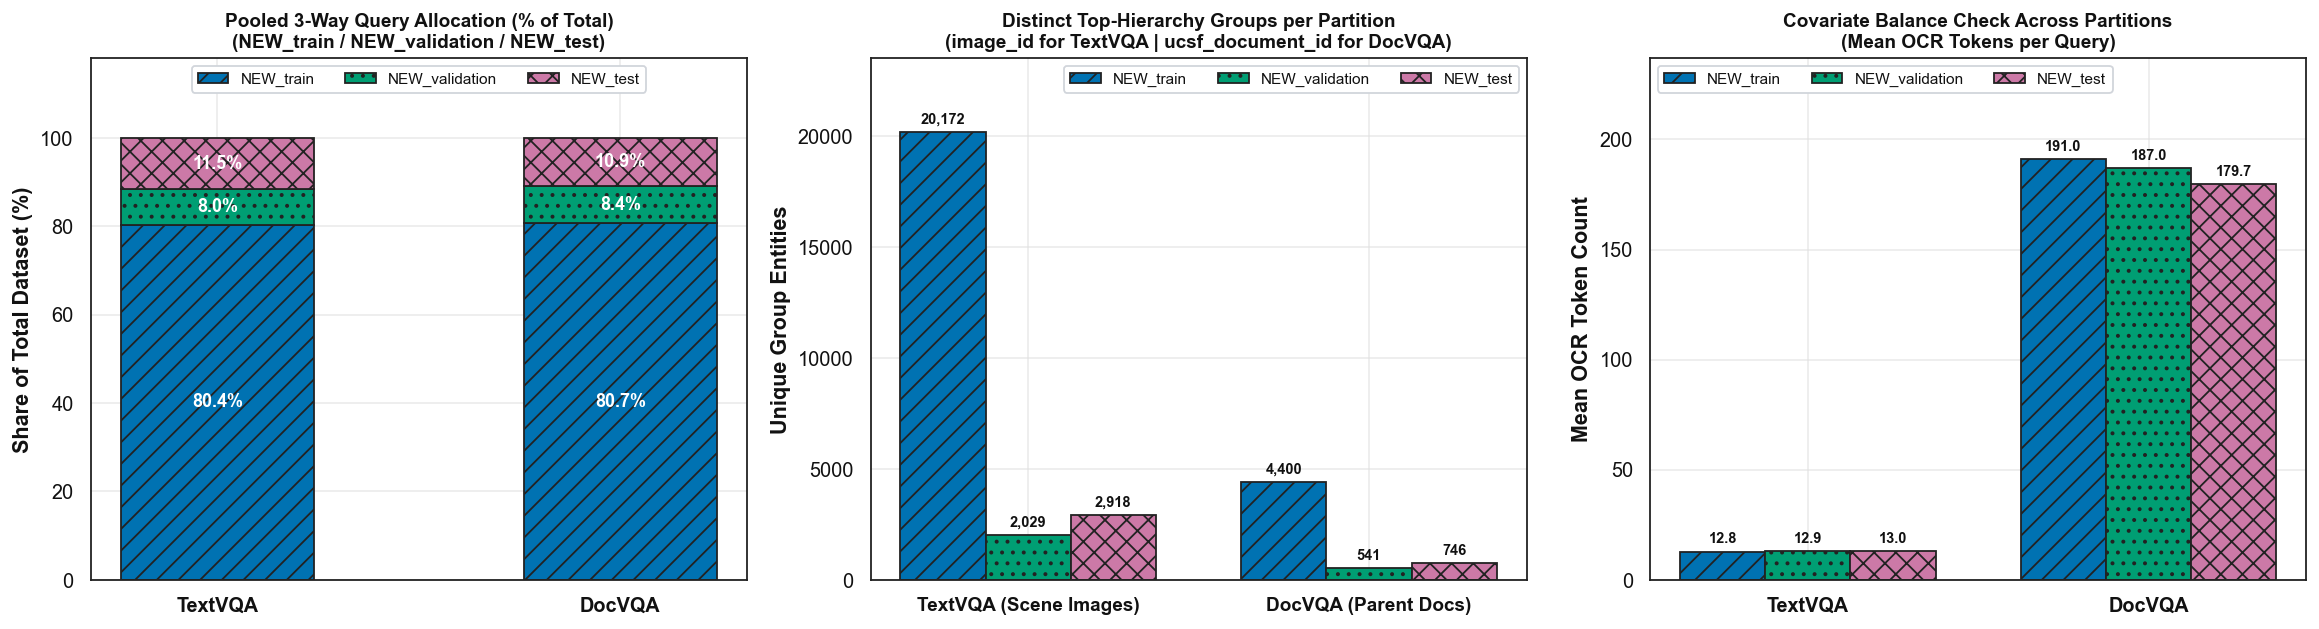

Saved partition summary figure -> DATA_PIPELINE/ALT_THREE_SPLITS/figures/polars_final_partition_summary.png


In [6]:
# ==============================================================================
# 6. PHASE 4A: EXPORT POOLED AGGREGATES, MANIFEST & RENDER AUDIT SUMMARY
# ==============================================================================

# 1. Export Pooled Top-Hierarchy Group Aggregate Tables (Parquet & CSV)
doc_agg_parquet = REL_SPLIT_DIR / "docvqa_document_aggregates_pooled.parquet"
doc_agg_csv = REL_SPLIT_DIR / "docvqa_document_aggregates_pooled.csv"
txt_agg_parquet = REL_SPLIT_DIR / "textvqa_image_aggregates_pooled.parquet"
txt_agg_csv = REL_SPLIT_DIR / "textvqa_image_aggregates_pooled.csv"

docvqa_doc_agg.write_parquet(doc_agg_parquet, compression="zstd")
docvqa_doc_agg.write_csv(doc_agg_csv)

textvqa_img_agg.write_parquet(txt_agg_parquet, compression="zstd")
textvqa_img_agg.write_csv(txt_agg_csv)

# 2. Export Compact Unified Row-Level Pooled Split Manifest (Parquet)
MANIFEST_COLS = [
    "sample_id",
    "domain_type",
    "split",
    "NEW_split",
    "question_id",
    "image_id",
    "group_key",
    "ocr_token_count",
]

df_unified_manifest = pl.concat(
    [
        df_textvqa_split.select(MANIFEST_COLS).with_columns(pl.lit("textvqa").alias("dataset")),
        df_docvqa_split.select(MANIFEST_COLS).with_columns(pl.lit("docvqa").alias("dataset")),
    ],
    how="vertical",
)

manifest_parquet_path = REL_SPLIT_DIR / "crossvqa_split_manifest_pooled.parquet"
df_unified_manifest.write_parquet(manifest_parquet_path, compression="zstd")

print(f"✓ DocVQA Pooled Document Aggregates -> {doc_agg_parquet.as_posix()} ({doc_agg_parquet.stat().st_size / 1024:.1f} KB) & CSV ({doc_agg_csv.stat().st_size / 1024:.1f} KB)")
print(f"✓ TextVQA Pooled Image Aggregates   -> {txt_agg_parquet.as_posix()} ({txt_agg_parquet.stat().st_size / 1024:.1f} KB) & CSV ({txt_agg_csv.stat().st_size / 1024:.1f} KB)")
print(f"✓ Unified Pooled Split Manifest     -> {manifest_parquet_path.as_posix()} ({manifest_parquet_path.stat().st_size / 1024:.1f} KB, {df_unified_manifest.height:,} rows)\n")

# 3. Tabulate Final 6-Partition Pooled Audit Summary
final_audit_rows = []
for ds_label, df_s in [("TextVQA", df_textvqa_split), ("DocVQA", df_docvqa_split)]:
    tot_q = df_s.height

    for part_name in ["NEW_train", "NEW_validation", "NEW_test"]:
        sub = df_s.filter(pl.col("NEW_split") == part_name)
        n_q = sub.height
        n_from_tr = sub.filter(pl.col("split") == "train").height
        n_from_va = sub.filter(pl.col("split") == "validation").height
        grp_counts = sub.group_by("group_key").agg(pl.len().alias("q_cnt"))["q_cnt"]
        moe_95 = 1.96 * math.sqrt(0.25 / n_q) * 100.0
        zero_ocr = int((sub["ocr_token_count"] == 0).sum())

        final_audit_rows.append({
            "Dataset": ds_label,
            "Partition": part_name,
            "Query Count": f"{n_q:,}",
            "% of Total (Pooled)": f"{n_q / tot_q * 100:.2f}%",
            "Origin (Train / Val)": f"{n_from_tr:,} / {n_from_va:,}",
            "Unique Images": f"{sub['image_id'].n_unique():,}",
            "Unique Group Keys": f"{sub['group_key'].n_unique():,}",
            "Mean / Max Qs per Group": f"{float(grp_counts.mean()):.2f} / {int(grp_counts.max())}",
            "95% MoE": f"±{moe_95:.2f}%",
            "Zero-OCR Queries": f"{zero_ocr:,} ({zero_ocr / n_q * 100:.2f}%)",
            "Cross-Split Leakage": "0 (Strictly Disjoint)",
        })

df_final_audit_pl = pl.DataFrame(final_audit_rows)
display_markdown_table(
    df_final_audit_pl,
    "#### Final CrossVQA De Novo Pooled 3-Way Partition Audit Table (`NEW_train`, `NEW_validation`, `NEW_test`)"
)

# 4. Render 3-Panel Partition Proportions & Covariate Balance Figure
fig, axes = plt.subplots(1, 3, figsize=(18.0, 5.0))
partitions = ["NEW_train", "NEW_validation", "NEW_test"]
part_colors = [PALETTE["train"], PALETTE["val"], PALETTE["test"]]
part_hatches = ["//", "..", "xx"]

x_ds = np.arange(2)
bottoms = np.zeros(2)

for sp_name, col, ht in zip(partitions, part_colors, part_hatches):
    cnts = [
        df_textvqa_split.filter(pl.col("NEW_split") == sp_name).height,
        df_docvqa_split.filter(pl.col("NEW_split") == sp_name).height,
    ]
    tots = [df_textvqa_split.height, df_docvqa_split.height]
    pcts = np.array([c / t * 100 for c, t in zip(cnts, tots)])
    bars = axes[0].bar(x_ds, pcts, width=0.48, bottom=bottoms, color=col, edgecolor=PALETTE["slate"], hatch=ht, label=sp_name)
    for b, pct, cnt, bot in zip(bars, pcts, cnts, bottoms):
        axes[0].annotate(
            f"{pct:.1f}%",
            xy=(b.get_x() + b.get_width()/2, bot + pct/2),
            ha="center", va="center", color="white", fontweight="bold", fontsize=10.0
        )
    bottoms += pcts

axes[0].set_title("Pooled 3-Way Query Allocation (% of Total)\n(NEW_train / NEW_validation / NEW_test)", fontsize=10.5)
axes[0].set_xticks(x_ds)
axes[0].set_xticklabels(["TextVQA", "DocVQA"], fontweight="bold", fontsize=11)
axes[0].set_ylabel("Share of Total Dataset (%)")
axes[0].set_ylim(0, 118)
axes[0].legend(loc="upper center", ncol=3, fontsize=8.5, facecolor="white", edgecolor="#D1D5DB", labelcolor="#111111", framealpha=1.0)

w = 0.25
for idx_p, (sp_name, col, ht) in enumerate(zip(partitions, part_colors, part_hatches)):
    grp_cnts = [
        df_textvqa_split.filter(pl.col("NEW_split") == sp_name)["group_key"].n_unique(),
        df_docvqa_split.filter(pl.col("NEW_split") == sp_name)["group_key"].n_unique(),
    ]
    bars = axes[1].bar(x_ds + (idx_p - 1) * w, grp_cnts, width=w, color=col, edgecolor=PALETTE["slate"], hatch=ht, label=sp_name)
    for b in bars:
        h = int(b.get_height())
        axes[1].annotate(f"{h:,}", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 3),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

axes[1].set_title("Distinct Top-Hierarchy Groups per Partition\n(image_id for TextVQA | ucsf_document_id for DocVQA)", fontsize=10.5)
axes[1].set_xticks(x_ds)
axes[1].set_xticklabels(["TextVQA (Scene Images)", "DocVQA (Parent Docs)"], fontweight="bold", fontsize=10.5)
axes[1].set_ylabel("Unique Group Entities")
axes[1].set_ylim(0, 23500)
axes[1].legend(loc="upper right", ncol=3, fontsize=8.5, facecolor="white", edgecolor="#D1D5DB", labelcolor="#111111", framealpha=1.0)

for idx_p, (sp_name, col, ht) in enumerate(zip(partitions, part_colors, part_hatches)):
    mean_ocr = [
        float(df_textvqa_split.filter(pl.col("NEW_split") == sp_name)["ocr_token_count"].mean()),
        float(df_docvqa_split.filter(pl.col("NEW_split") == sp_name)["ocr_token_count"].mean()),
    ]
    bars = axes[2].bar(x_ds + (idx_p - 1) * w, mean_ocr, width=w, color=col, edgecolor=PALETTE["slate"], hatch=ht, label=sp_name)
    for b in bars:
        val = b.get_height()
        axes[2].annotate(f"{val:.1f}", xy=(b.get_x() + b.get_width()/2, val), xytext=(0, 3),
                         textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

axes[2].set_title("Covariate Balance Check Across Partitions\n(Mean OCR Tokens per Query)", fontsize=10.5)
axes[2].set_xticks(x_ds)
axes[2].set_xticklabels(["TextVQA", "DocVQA"], fontweight="bold", fontsize=11)
axes[2].set_ylabel("Mean OCR Token Count")
axes[2].set_ylim(0, max(float(df_docvqa_split["ocr_token_count"].mean()) * 1.25, 200))
axes[2].legend(loc="upper left", ncol=3, fontsize=8.5, facecolor="white", edgecolor="#D1D5DB", labelcolor="#111111", framealpha=1.0)

plt.tight_layout()
final_fig_path = REL_FIG_DIR / "polars_final_partition_summary.png"
plt.savefig(final_fig_path, bbox_inches="tight")
plt.show()
print(f"Saved partition summary figure -> {final_fig_path.as_posix()}")

In [7]:
# ==============================================================================
# 7. PHASE 4B: COMMIT & PUSH GENERATED POOLED ARTIFACTS TO GITHUB (COLAB & LOCAL)
# ==============================================================================
import getpass
import shutil
import subprocess

def sync_pooled_splits_to_github(
    repo_slug: str = "NhanChanDeo/VQA_Final_Thesis.git",
    commit_msg: str = "feat(alt-three-splits): add de novo pooled 3-way group aggregates and split manifest",
    interactive_prompt: bool = False,
) -> None:
    token = os.environ.get("GITHUB_TOKEN")
    if IN_COLAB and not token:
        try:
            from google.colab import userdata  # type: ignore
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token and interactive_prompt:
        token = getpass.getpass("Enter GitHub Personal Access Token (or press Enter to skip push): ").strip()
    if not token:
        print("ℹ️ Skipping GitHub push (no GITHUB_TOKEN set). Files are saved in DATA_PIPELINE/ALT_THREE_SPLITS/splits/.")
        return

    repo_url = f"https://{token}@github.com/{repo_slug}"
    clone_dir = Path("/content/VQA_Final_Thesis_repo") if IN_COLAB else Path("../VQA_Final_Thesis_sync_tmp")

    if clone_dir.exists():
        shutil.rmtree(clone_dir)

    print(f"Cloning {repo_slug} into temporary worktree...")
    subprocess.run(["git", "clone", repo_url, str(clone_dir)], check=True)

    target_split_dir = clone_dir / "DATA_PIPELINE" / "ALT_THREE_SPLITS" / "splits"
    target_fig_dir = clone_dir / "DATA_PIPELINE" / "ALT_THREE_SPLITS" / "figures"
    target_split_dir.mkdir(parents=True, exist_ok=True)
    target_fig_dir.mkdir(parents=True, exist_ok=True)

    for item in REL_SPLIT_DIR.glob("*"):
        if item.is_file():
            shutil.copy2(item, target_split_dir / item.name)
            print(f"  ✓ Copied split artifact: {item.name}")

    for item in REL_FIG_DIR.glob("*.png"):
        if item.is_file():
            shutil.copy2(item, target_fig_dir / item.name)
            print(f"  ✓ Copied figure: {item.name}")

    subprocess.run(["git", "config", "user.name", "NhanChanDeo"], cwd=clone_dir, check=True)
    subprocess.run(["git", "config", "user.email", "pipeline@vqa-thesis.local"], cwd=clone_dir, check=True)
    subprocess.run(["git", "add", "DATA_PIPELINE/ALT_THREE_SPLITS/"], cwd=clone_dir, check=True)

    status = subprocess.run(["git", "status", "--porcelain"], cwd=clone_dir, capture_output=True, text=True).stdout.strip()
    if not status:
        print("ℹ️ All ALT_THREE_SPLITS artifacts in origin/main are already identical and up-to-date.")
        return

    subprocess.run(["git", "commit", "-m", commit_msg], cwd=clone_dir, check=True)
    subprocess.run(["git", "push", "origin", "HEAD:main"], cwd=clone_dir, check=True)
    print("\n🎉 Successfully committed and pushed ALT_THREE_SPLITS artifacts to GitHub (origin/main)!")

sync_pooled_splits_to_github(interactive_prompt=False)

ℹ️ Skipping GitHub push (no GITHUB_TOKEN set). Files are saved in DATA_PIPELINE/ALT_THREE_SPLITS/splits/.
